In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("Twitter_Data.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nColumn Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df.iloc[:, -1].value_counts())

Dataset Shape: (162980, 2)

First 5 records:


,clean_text,category
0,when modi promised “minimum government maximum...,-1.0
1,talk all the nonsense and continue all the dra...,0.0
2,what did just say vote for modi welcome bjp t...,1.0
3,asking his supporters prefix chowkidar their n...,1.0
4,answer who among these the most powerful world...,1.0



Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162980 entries, 0 to 162979
Data columns (total 2 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   clean_text  162976 non-null  object 
 1   category    162973 non-null  float64
dtypes: float64(1), object(1)
memory usage: 2.5+ MB
None

Missing Values:
clean_text    4
category      7
dtype: int64

Sentiment Distribution:
category
 1.0    72250
 0.0    55213
-1.0    35510
Name: count, dtype: int64


Data cleaning

In [3]:
# Keep the original dataset unchanged
df_clean = df.copy()

print("Original shape:", df_clean.shape)

# Remove rows with missing text or sentiment labels
df_clean = df_clean.dropna(
    subset=["clean_text", "category"]
)

# Remove empty or whitespace-only text
df_clean["clean_text"] = df_clean["clean_text"].astype(str)

df_clean = df_clean[
    df_clean["clean_text"].str.strip().ne("")
]

# Remove duplicate records
df_clean = df_clean.drop_duplicates(
    subset=["clean_text", "category"]
)

# Convert sentiment labels to integers
df_clean["category"] = df_clean["category"].astype(int)

# Validate labels
valid_labels = {-1, 0, 1}

assert set(df_clean["category"].unique()).issubset(valid_labels)

# Rename columns for clarity
df_clean = df_clean.rename(
    columns={
        "clean_text": "text",
        "category": "sentiment"
    }
)

df_clean = df_clean.reset_index(drop=True)

print("\nCleaned shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nSentiment distribution:")
print(df_clean["sentiment"].value_counts())

print("\nSample records:")
display(df_clean.head())

Original shape: (162980, 2)

Cleaned shape: (162968, 2)

Missing values:
text         0
sentiment    0
dtype: int64

Sentiment distribution:
sentiment
 1    72249
 0    55210
-1    35509
Name: count, dtype: int64

Sample records:


,text,sentiment
0,when modi promised “minimum government maximum...,-1
1,talk all the nonsense and continue all the dra...,0
2,what did just say vote for modi welcome bjp t...,1
3,asking his supporters prefix chowkidar their n...,1
4,answer who among these the most powerful world...,1


Verify the cleaned dataset

In [4]:
print("Total records:", len(df_clean))
print("Unique sentiments:", sorted(df_clean["sentiment"].unique()))

assert df_clean["text"].notna().all()
assert df_clean["sentiment"].notna().all()
assert df_clean["text"].str.strip().ne("").all()
assert df_clean["sentiment"].isin([-1, 0, 1]).all()

print("\nAll data validation checks passed!")

Total records: 162968
Unique sentiments: [np.int64(-1), np.int64(0), np.int64(1)]

All data validation checks passed!


Exploratory Data Analysis (EDA)

In [5]:
# Calculate the number of words in each tweet
df_clean["word_count"] = df_clean["text"].apply(
    lambda text: len(text.split())
)

# Statistical summary
print(df_clean["word_count"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

count    162968.000000
mean         20.080826
std          10.879516
min           1.000000
25%          11.000000
50%          18.000000
75%          29.000000
90%          36.000000
95%          38.000000
99%          42.000000
max          52.000000
Name: word_count, dtype: float64


Visualize sentence-length distribution

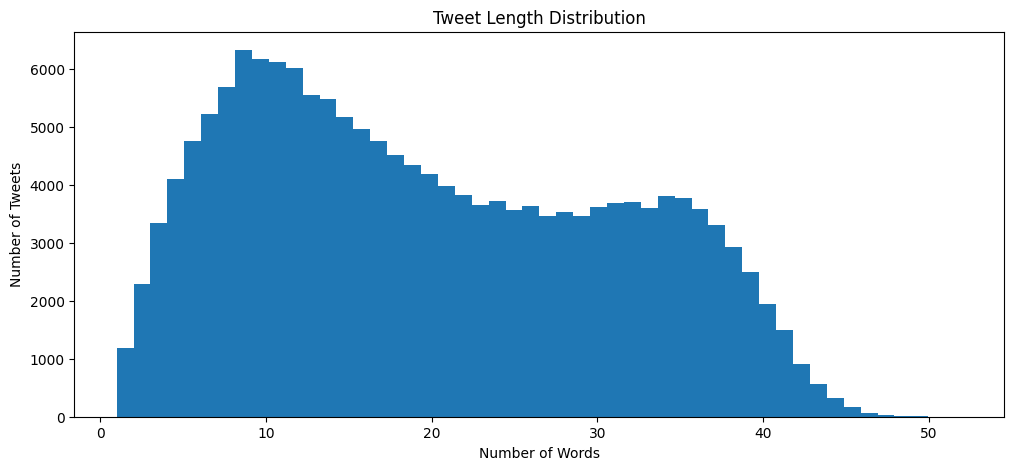

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(
    df_clean["word_count"],
    bins=50
)

plt.title("Tweet Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Tweets")

plt.show()

Compare sentence lengths across sentiment classes

In [7]:
print(
    df_clean.groupby("sentiment")["word_count"]
    .describe()
)

             count       mean        std  min   25%   50%   75%   max
sentiment                                                            
-1         35509.0  23.880622  10.307720  1.0  15.0  24.0  33.0  51.0
 0         55210.0  14.271364   9.075051  1.0   7.0  12.0  19.0  52.0
 1         72249.0  22.652673  10.598821  1.0  14.0  22.0  32.0  50.0


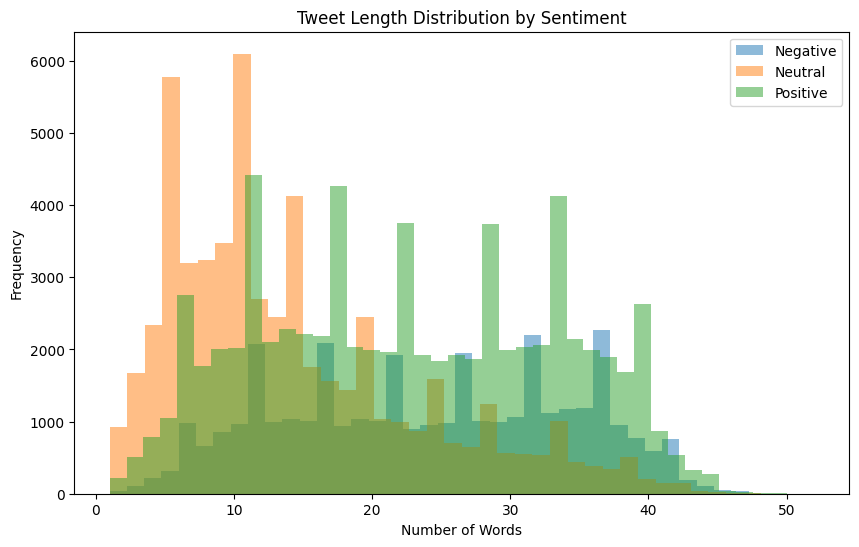

In [8]:
plt.figure(figsize=(10, 6))

for sentiment in [-1, 0, 1]:

    lengths = df_clean[
        df_clean["sentiment"] == sentiment
    ]["word_count"]

    plt.hist(
        lengths,
        bins=40,
        alpha=0.5,
        label={
            -1: "Negative",
             0: "Neutral",
             1: "Positive"
        }[sentiment]
    )

plt.title("Tweet Length Distribution by Sentiment")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.legend()

plt.show()

Inspect actual examples

In [9]:
for sentiment, label in [
    (-1, "Negative"),
    (0, "Neutral"),
    (1, "Positive")
]:

    print(f"\n{label} Examples")

    samples = df_clean[
        df_clean["sentiment"] == sentiment
    ]["text"].sample(5, random_state=42)

    for text in samples:
        print("-", text)


Negative Examples
- desperately waiting watch the not movie review upcoming narendra modi please the first day release 
- madam kanpur and akbarpur seat will loose candidates having very bad image there modi alone cannot make such the extent the damage done present mps needed someone big from kanpur
- everything that happened under nehru gandhi due their vision and selflessness whereas everything that happened under modi also due nehru gandhi vision and merely uses bolster his vanity isnt stupid logic
- funny that such renowned writer doesnt know that previous law required the villagers approve acquisition whereas what modi passed was only and that one could ever court future pls check facts you failed writer
- and all this possible only due the efforts invisible modi post 2014 prior that indian scientists never existed for that matter india was the dark ages what attention seeking clown this guy

Neutral Examples
- there reason why modi called feku 
- stands reason that this was neve

Prepare data for LSTM

In [10]:
# Keep only the original text and sentiment columns
data = df_clean[["text", "sentiment"]].copy()

print(data.head())
print(data.shape)

                                                text  sentiment
0  when modi promised “minimum government maximum...         -1
1  talk all the nonsense and continue all the dra...          0
2  what did just say vote for modi  welcome bjp t...          1
3  asking his supporters prefix chowkidar their n...          1
4  answer who among these the most powerful world...          1
(162968, 2)


Convert labels


In [11]:
label_mapping = {
    -1: 0,  # Negative
     0: 1,  # Neutral
     1: 2   # Positive
}

data["sentiment"] = data["sentiment"].map(label_mapping)

print(data["sentiment"].value_counts().sort_index())

sentiment
0    35509
1    55210
2    72249
Name: count, dtype: int64


Split the dataset

In [12]:
from sklearn.model_selection import train_test_split

# First separate the test set
train_val, test_data = train_test_split(
    data,
    test_size=0.15,
    random_state=42,
    stratify=data["sentiment"]
)

# Split remaining data into training and validation
train_data, val_data = train_test_split(
    train_val,
    test_size=0.17647,
    random_state=42,
    stratify=train_val["sentiment"]
)

print("Training samples:", len(train_data))
print("Validation samples:", len(val_data))
print("Testing samples:", len(test_data))

Training samples: 114077
Validation samples: 24445
Testing samples: 24446


Initialize tokenizer

In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_SEQUENCE_LENGTH = 45
MAX_VOCAB_SIZE = 30000

tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    oov_token="<OOV>"
)

# Fit ONLY on training text
tokenizer.fit_on_texts(train_data["text"])

print("Total vocabulary:", len(tokenizer.word_index))
print("Configured vocabulary limit:", MAX_VOCAB_SIZE)

Total vocabulary: 90925
Configured vocabulary limit: 30000


Convert text into sequences

In [14]:
X_train = tokenizer.texts_to_sequences(train_data["text"])
X_val = tokenizer.texts_to_sequences(val_data["text"])
X_test = tokenizer.texts_to_sequences(test_data["text"])

# Apply padding
X_train = pad_sequences(
    X_train,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    X_val,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post"
)

# Extract labels
y_train = train_data["sentiment"].values
y_val = val_data["sentiment"].values
y_test = test_data["sentiment"].values

print("Training shape:", X_train.shape, y_train.shape)
print("Validation shape:", X_val.shape, y_val.shape)
print("Testing shape:", X_test.shape, y_test.shape)

Training shape: (114077, 45) (114077,)
Validation shape: (24445, 45) (24445,)
Testing shape: (24446, 45) (24446,)


Inspect a tokenized example

In [15]:
sample_index = 0

print("Original text:")
print(train_data.iloc[sample_index]["text"])

print("\nTokenized sequence:")
print(X_train[sample_index])

print("\nActual label:")
print(y_train[sample_index])

print("\nWord index:")
print(tokenizer.word_index.get("<OOV>"))

Original text:
says why you dint question when modi fought elec from places was then fighting for the 1st time loksabha elec and rahul sitting from years thats the difference 

Tokenized sequence:
[  84   34    6 3672  229   43    2 1420 9719   19 1995   18   62  621
    5    3  969   52 1818 9719    4   53 1313   19   50  181    3  419
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0]

Actual label:
1

Word index:
1


Calculate vocabulary coverage

In [16]:
word_index = tokenizer.word_index

print("Total unique words:", len(word_index))

print("Words within vocabulary limit:",
      sum(1 for index in word_index.values()
          if index < MAX_VOCAB_SIZE))

print("Maximum sequence length:", MAX_SEQUENCE_LENGTH)

Total unique words: 90925
Words within vocabulary limit: 29999
Maximum sequence length: 45


Prepare GloVe pretrained embeddings

In [17]:
!wget -c --show-progress \
"https://zenodo.org/records/3237458/files/glove.twitter.27B.100d.txt.gz?download=1" \
-O glove.twitter.27B.100d.txt.gz

--2026-11-19 08:17:22--  https://zenodo.org/records/3237458/files/glove.twitter.27B.100d.txt.gz?download=1
Resolving zenodo.org (zenodo.org)... 137.138.121.78, 188.185.42.113, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|137.138.121.78|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 405932996 (387M) [text/plain]
Saving to: ‘glove.twitter.27B.100d.txt.gz’

glove.twitter.27B.1 100%[===================>] 387.13M  2.56MB/s    in 2m 32s  

2026-11-19 08:19:55 (2.54 MB/s) - ‘glove.twitter.27B.100d.txt.gz’ saved [405932996/405932996]



In [18]:
!gunzip -k glove.twitter.27B.100d.txt.gz

Create the embedding matrix

In [19]:
import numpy as np

EMBEDDING_DIM = 100
MAX_VOCAB_SIZE = 30000

# Initialize embedding matrix
embedding_matrix = np.zeros(
    (MAX_VOCAB_SIZE, EMBEDDING_DIM),
    dtype=np.float32
)

# Only words within our tokenizer vocabulary are needed
vocabulary_words = {
    word
    for word, index in tokenizer.word_index.items()
    if 1 < index < MAX_VOCAB_SIZE
}

words_found = 0

# Read GloVe and extract only the vectors we need
with open(
    "glove.twitter.27B.100d.txt",
    encoding="utf-8"
) as file:

    for line in file:

        values = line.rstrip().split(" ")

        word = values[0]

        if word not in vocabulary_words:
            continue

        vector = np.asarray(
            values[1:],
            dtype=np.float32
        )

        index = tokenizer.word_index[word]

        embedding_matrix[index] = vector

        words_found += 1

print("Embedding matrix shape:", embedding_matrix.shape)
print("Words found:", words_found)
print("Words required:", len(vocabulary_words))

coverage = words_found / len(vocabulary_words) * 100

print(f"Vocabulary coverage: {coverage:.2f}%")

Embedding matrix shape: (30000, 100)
Words found: 22333
Words required: 29998
Vocabulary coverage: 74.45%


Verify embeddings

In [20]:
word = "love"

index = tokenizer.word_index.get(word)

print("Word:", word)
print("Tokenizer index:", index)

if index is not None and index < MAX_VOCAB_SIZE:

    vector = embedding_matrix[index]

    print("Vector shape:", vector.shape)
    print("First 10 values:", vector[:10])
    print("Vector norm:", np.linalg.norm(vector))

Word: love
Tokenizer index: 245
Vector shape: (100,)
First 10 values: [-0.48371  -0.27318  -0.04684   0.70274  -0.56301  -0.17214   0.81775
 -0.066641  0.020224 -0.23878 ]
Vector norm: 6.7218137


Verify our embedding matrix

In [21]:
print("Embedding matrix shape:", embedding_matrix.shape)

print("Padding vector norm:",
      np.linalg.norm(embedding_matrix[0]))

print("OOV vector norm:",
      np.linalg.norm(embedding_matrix[1]))

print("Total non-zero embedding vectors:",
      np.count_nonzero(np.linalg.norm(embedding_matrix, axis=1)))

Embedding matrix shape: (30000, 100)
Padding vector norm: 0.0
OOV vector norm: 0.0
Total non-zero embedding vectors: 22333


Build both models

In [22]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense

# Model configuration
MAX_VOCAB_SIZE = 30000
MAX_SEQUENCE_LENGTH = 45
EMBEDDING_DIM = 100
NUM_CLASSES = 3

def build_sentiment_model(pretrained_embeddings=None):

    model = Sequential()

    # Input + Embedding
    if pretrained_embeddings is None:

        # Randomly initialized embeddings
        model.add(
            Embedding(
                input_dim=MAX_VOCAB_SIZE,
                output_dim=EMBEDDING_DIM,
                mask_zero=True,
                trainable=True
            )
        )

    else:

        # Pretrained GloVe embeddings
        model.add(
            Embedding(
                input_dim=MAX_VOCAB_SIZE,
                output_dim=EMBEDDING_DIM,
                weights=[pretrained_embeddings],
                mask_zero=True,
                trainable=True
            )
        )

    # LSTM layer
    model.add(
        LSTM(64)
    )

    # Regularization
    model.add(
        Dropout(0.3)
    )

    # Fully connected layer
    model.add(
        Dense(32, activation="relu")
    )

    # Output layer
    model.add(
        Dense(NUM_CLASSES, activation="softmax")
    )

    # Compile
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

Initialize both models

In [23]:
# Model 1: Randomly initialized embeddings
model_random = build_sentiment_model()

# Model 2: Pretrained GloVe embeddings
model_glove = build_sentiment_model(
    pretrained_embeddings=embedding_matrix
)

print("RANDOM EMBEDDING MODEL")
model_random.summary()

print("\nGLOVE EMBEDDING MODEL")
model_glove.summary()

RANDOM EMBEDDING MODEL


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,000,000 (11.44 MB)

 Trainable params: 3,000,000 (11.44 MB)

 Non-trainable params: 0 (0.00 B)

Build both models
Cell 1 — Import and define configuration

In [24]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dropout, Dense

MAX_VOCAB_SIZE = 30000
MAX_SEQUENCE_LENGTH = 45
EMBEDDING_DIM = 100
LSTM_UNITS = 64
NUM_CLASSES = 3

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


Cell 2 — Create the randomly initialized embedding model

In [25]:
random_embedding_model = Sequential([
    Input(shape=(MAX_SEQUENCE_LENGTH,)),

    Embedding(
        input_dim=MAX_VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        mask_zero=True,
        trainable=True
    ),

    LSTM(LSTM_UNITS),

    Dropout(0.3),

    Dense(32, activation="relu"),

    Dense(NUM_CLASSES, activation="softmax")
])

random_embedding_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

random_embedding_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 45, 100)        │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,044,419 (11.61 MB)

 Trainable params: 3,044,419 (11.61 MB)

 Non-trainable params: 0 (0.00 B)

Cell 3 — Create the GloVe embedding model

In [26]:
glove_embedding_model = Sequential([
    Input(shape=(MAX_SEQUENCE_LENGTH,)),

    Embedding(
        input_dim=MAX_VOCAB_SIZE,
        output_dim=EMBEDDING_DIM,
        weights=[embedding_matrix],
        mask_zero=True,
        trainable=True
    ),

    LSTM(LSTM_UNITS),

    Dropout(0.3),

    Dense(32, activation="relu"),

    Dense(NUM_CLASSES, activation="softmax")
])

glove_embedding_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

glove_embedding_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 45, 100)        │     3,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,044,419 (11.61 MB)

 Trainable params: 3,044,419 (11.61 MB)

 Non-trainable params: 0 (0.00 B)

Step 1 — Set up training callbacks
We'll use:
- EarlyStopping: Stops training if validation loss stops improving.
- ReduceLROnPlateau: Reduces the learning rate when validation loss plateaus.
- ModelCheckpoint: Saves the best model based on validation loss.
Cell 1 — Verify GPU

In [27]:
import tensorflow as tf

print("GPU Available:", tf.config.list_physical_devices("GPU"))

GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Cell 2 — Configure callbacks

In [28]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

random_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        filepath="best_random_embedding_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

Step 2 — Train the random embedding model

In [29]:
EPOCHS = 10
BATCH_SIZE = 128

history_random = random_embedding_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=random_callbacks,
    verbose=1
)

Epoch 1/10
890/892 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7469 - loss: 0.5879
Epoch 1: val_loss improved from None to 0.17034, saving model to best_random_embedding_model.keras

Epoch 1: finished saving model to best_random_embedding_model.keras
892/892 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8683 - loss: 0.3543 - val_accuracy: 0.9515 - val_loss: 0.1703 - learning_rate: 0.0010
Epoch 2/10
892/892 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9627 - loss: 0.1299
Epoch 2: val_loss improved from 0.17034 to 0.13442, saving model to best_random_embedding_model.keras

Epoch 2: finished saving model to best_random_embedding_model.keras
892/892 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9641 - loss: 0.1218 - val_accuracy: 0.9588 - val_loss: 0.1344 - learning_rate: 0.0010
Epoch 3/10
891/892 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9760 - loss: 0.0786
Epoch 3: val_loss improved from 0.13442 to 0.12106, saving model to best_random_embedding_model.keras

Epoch 3: fini

Step 3 — Visualize training performance

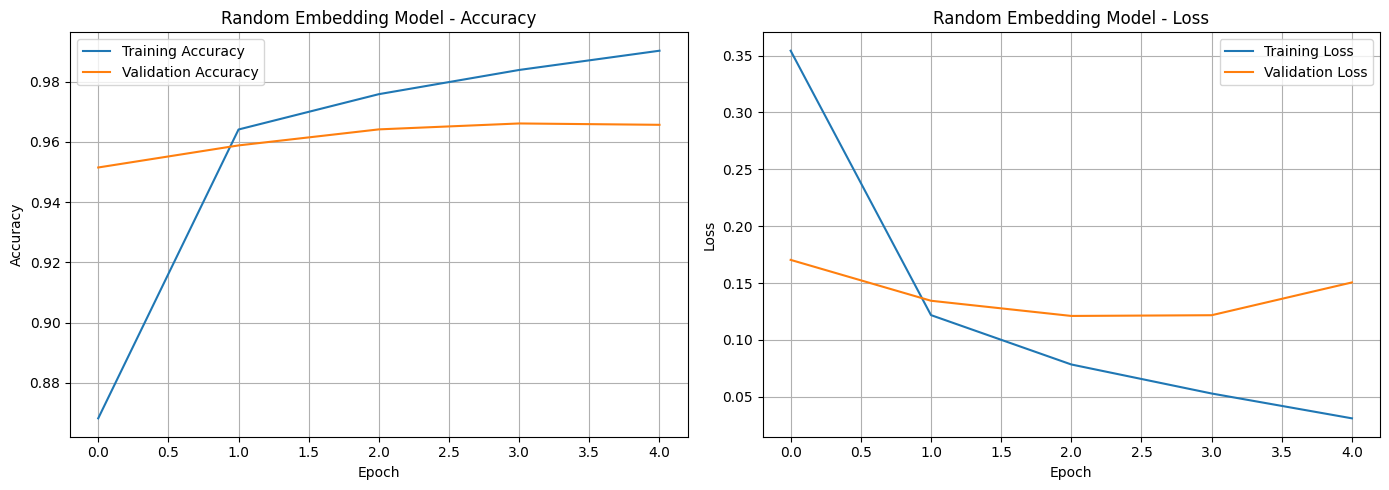

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_random.history["accuracy"], label="Training Accuracy")
plt.plot(history_random.history["val_accuracy"], label="Validation Accuracy")
plt.title("Random Embedding Model - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_random.history["loss"], label="Training Loss")
plt.plot(history_random.history["val_loss"], label="Validation Loss")
plt.title("Random Embedding Model - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

GloVe training callbacks

In [31]:
glove_callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=1,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        filepath="best_glove_embedding_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

Train GloVe model

In [32]:
history_glove = glove_embedding_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=glove_callbacks,
    verbose=1
)

Epoch 1/10
888/892 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6991 - loss: 0.6775
Epoch 1: val_loss improved from None to 0.17126, saving model to best_glove_embedding_model.keras

Epoch 1: finished saving model to best_glove_embedding_model.keras
892/892 ━━━━━━━━━━━━━━━━━━━━ 14s 13ms/step - accuracy: 0.8288 - loss: 0.4326 - val_accuracy: 0.9478 - val_loss: 0.1713 - learning_rate: 0.0010
Epoch 2/10
891/892 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9551 - loss: 0.1488
Epoch 2: val_loss improved from 0.17126 to 0.10971, saving model to best_glove_embedding_model.keras

Epoch 2: finished saving model to best_glove_embedding_model.keras
892/892 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.9604 - loss: 0.1325 - val_accuracy: 0.9669 - val_loss: 0.1097 - learning_rate: 0.0010
Epoch 3/10
888/892 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9761 - loss: 0.0829
Epoch 3: val_loss improved from 0.10971 to 0.10410, saving model to best_glove_embedding_model.keras

Epoch 3: finished

Plot GloVe training performance

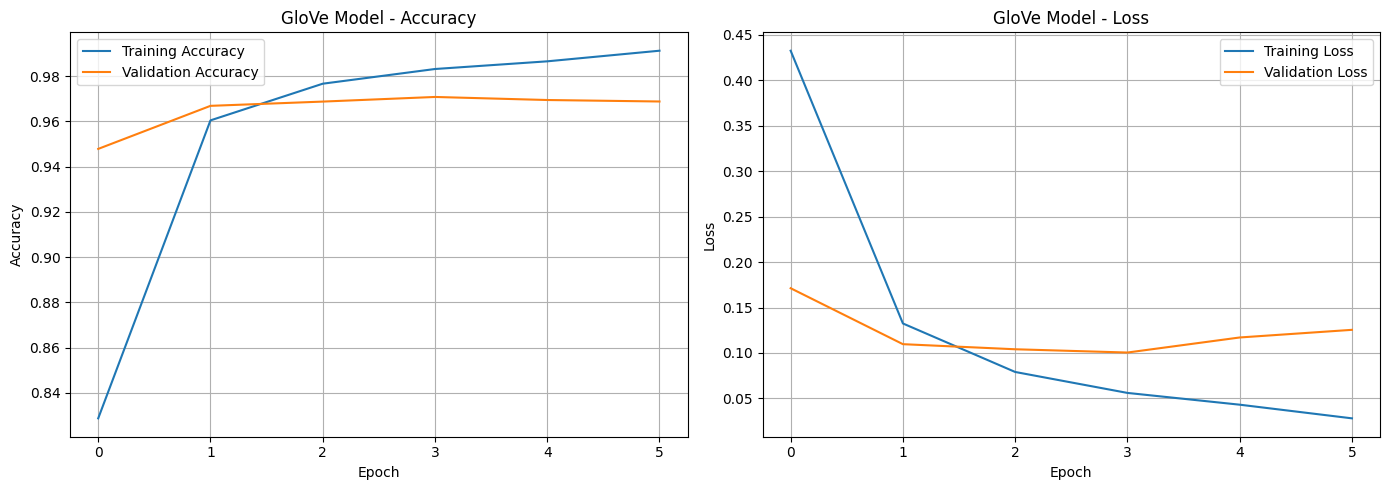

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_glove.history["accuracy"], label="Training Accuracy")
plt.plot(history_glove.history["val_accuracy"], label="Validation Accuracy")
plt.title("GloVe Model - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history_glove.history["loss"], label="Training Loss")
plt.plot(history_glove.history["val_loss"], label="Validation Loss")
plt.title("GloVe Model - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Load the best saved checkpoints

In [34]:
import tensorflow as tf

best_random_model = tf.keras.models.load_model(
    "best_random_embedding_model.keras"
)

best_glove_model = tf.keras.models.load_model(
    "best_glove_embedding_model.keras"
)

print("Best checkpoints loaded successfully!")

Best checkpoints loaded successfully!


Evaluate and compare

In [35]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

class_names = ["Negative", "Neutral", "Positive"]

models = {
    "Random Embeddings": best_random_model,
    "GloVe Embeddings": best_glove_model
}

results = []

for model_name, model in models.items():

    test_loss, test_accuracy = model.evaluate(
        X_test,
        y_test,
        verbose=0
    )

    predictions = model.predict(X_test, verbose=0)

    y_pred = np.argmax(predictions, axis=1)

    results.append({
        "Model": model_name,
        "Test Loss": test_loss,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro"
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro"
        ),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),
        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

    print(f"\n{'='*60}")
    print(model_name)
    print(f"{'='*60}")

    print(classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        digits=4
    ))

comparison_df = pd.DataFrame(results)

comparison_df


Random Embeddings
              precision    recall  f1-score   support

    Negative     0.9195    0.9459    0.9325      5326
     Neutral     0.9883    0.9679    0.9780      8282
    Positive     0.9653    0.9669    0.9661     10838

    accuracy                         0.9627     24446
   macro avg     0.9577    0.9602    0.9589     24446
weighted avg     0.9631    0.9627    0.9628     24446


GloVe Embeddings
              precision    recall  f1-score   support

    Negative     0.9549    0.9495    0.9522      5326
     Neutral     0.9896    0.9736    0.9815      8282
    Positive     0.9664    0.9810    0.9736     10838

    accuracy                         0.9716     24446
   macro avg     0.9703    0.9680    0.9691     24446
weighted avg     0.9717    0.9716    0.9716     24446



,Model,Test Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,Random Embeddings,0.132664,0.962652,0.95769,0.960228,0.958861,0.962799
1,GloVe Embeddings,0.104455,0.971611,0.97027,0.968014,0.969099,0.971619


Cell 3 — Visualize confusion matrices

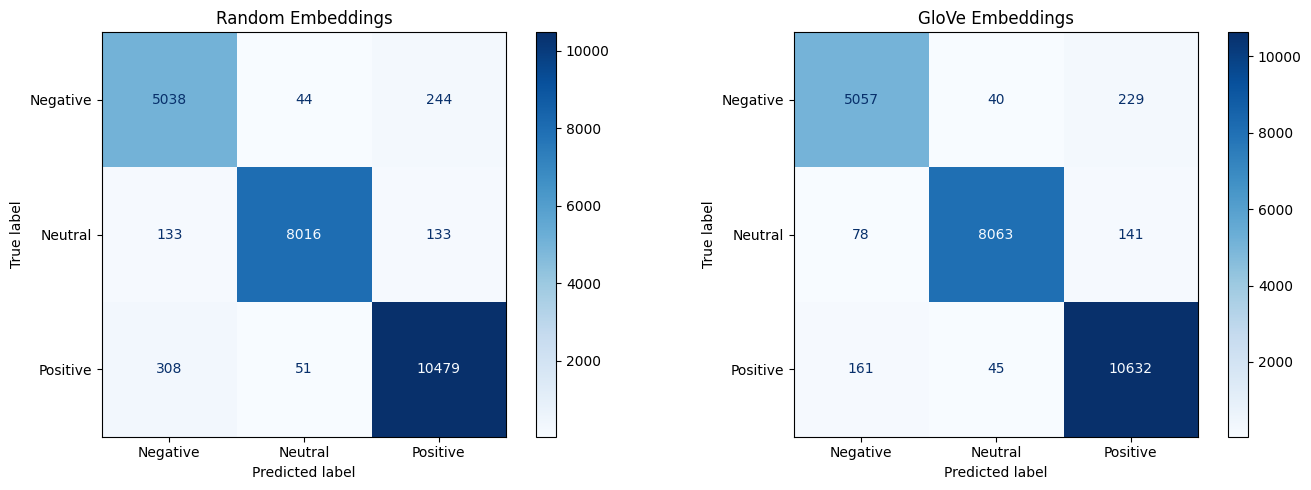

In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (model_name, model) in zip(axes, models.items()):

    y_pred = np.argmax(
        model.predict(X_test, verbose=0),
        axis=1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        display_labels=class_names,
        cmap="Blues",
        ax=ax,
        values_format="d"
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()

Let's inspect where the GloVe model makes mistakes

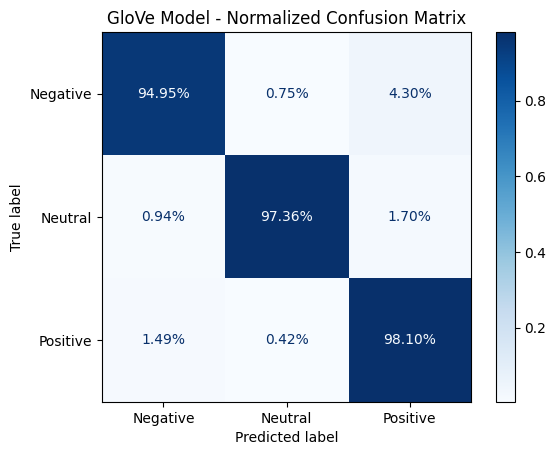

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

y_pred_glove = np.argmax(
    best_glove_model.predict(X_test, verbose=0),
    axis=1
)

cm = confusion_matrix(
    y_test,
    y_pred_glove,
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot(cmap="Blues", values_format=".2%")
plt.title("GloVe Model - Normalized Confusion Matrix")
plt.show()

save our deployment artifacts

In [38]:
import pickle
import json
import zipfile
from google.colab import files

# 1. Save trained model
best_glove_model.save("sentiment_model.keras")

# 2. Save tokenizer
with open("tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

# 3. Save configuration
config = {
    "max_vocab_size": 30000,
    "max_sequence_length": 45,
    "embedding_dim": 100,
    "num_classes": 3,
    "class_mapping": {
        "0": "Negative",
        "1": "Neutral",
        "2": "Positive"
    },
    "model_type": "LSTM",
    "embedding_type": "Twitter GloVe 100d",
    "lstm_units": 64
}

with open("config.json", "w") as file:
    json.dump(config, file, indent=4)

# 4. Package everything
with zipfile.ZipFile("sentimentai_artifacts.zip", "w") as zip_file:
    zip_file.write("sentiment_model.keras")
    zip_file.write("tokenizer.pkl")
    zip_file.write("config.json")

# 5. Download to your computer
files.download("sentimentai_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>